# Gradient Descent, SGD & Mini-Batch: Practice Notebook

**How to use this notebook**
1. Run the setup cell below (click ▶ or press `Shift+Enter`).
2. Read each section, then do the problems. Hand-calculation problems: work them on paper first, then type the number.
3. Coding problems: fill in the function, then run the cell. The checker runs tests on your code.
4. Stuck? Uncomment `hint(...)`. Still stuck? Uncomment `solution(...)`.
5. The cells marked **Demo** are already written. Run them to see pictures of what your code is doing.
6. The **Viz** problems (V1 to V5) have you build the charts yourself. See "Data viz practice" below.

**Roadmap:** the 1-D idea → linear regression as a loss to minimize → batch GD → SGD → mini-batch → head-to-head comparison → concept check.

Formula sheet: `gradient-descent-formulas.md`

In [1]:
# ▶ RUN THIS CELL FIRST (answers are encoded so you can't peek by scrolling)
import base64 as _b64, json as _json, math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PathCollection, LineCollection
from matplotlib.contour import ContourSet

_D = _json.loads(_b64.b64decode("..."))
exec(_D["ref"])           # reference implementations used by the checkers
_solved = set()

# ---------- the data used throughout ----------
rng = np.random.default_rng(42)
n = 200
x = rng.uniform(0, 2, n)                       # feature
y = 4 + 3 * x + rng.normal(0, 0.5, n)          # true line: y = 3x + 4, plus noise

x_tiny = np.array([1.0, 2.0, 3.0])             # tiny dataset for hand calculations
y_tiny = np.array([2.0, 4.0, 7.0])

def mse(w, b, x, y):
    """Mean squared error of the line y_hat = w*x + b."""
    return np.mean((w * x + b - y) ** 2)

w_best, b_best = np.polyfit(x, y, 1)           # exact least-squares answer (our target)
_X, _Y, _XT, _YT = x.copy(), y.copy(), x_tiny.copy(), y_tiny.copy()   # private copies for checkers

# ---------- plotting style ----------
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # batch GD, SGD, mini-batch, extra
INK, MUTED = "#0b0b0b", "#8a8984"                                          # text / reference lines, recessive gray
plt.rcParams.update({
    "figure.figsize": (7, 4), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
})

def losses_along(path, x=None, y=None):
    """Full-dataset MSE at every (w, b) in a path."""
    x = _X if x is None else x; y = _Y if y is None else y
    p = np.asarray(path)
    return np.mean((p[:, :1] * x + p[:, 1:] - y) ** 2, axis=1)

def plot_contour(paths, ax=None, wlim=(-0.5, 5), blim=(-0.5, 6), title=None):
    """Draw MSE contours over (w, b) and overlay optimizer paths: {label: (path, color)}."""
    ax = ax or plt.gca()
    W, B = np.meshgrid(np.linspace(*wlim, 200), np.linspace(*blim, 200))
    L = np.mean((W[..., None] * _X + B[..., None] - _Y) ** 2, axis=-1)
    ax.contour(W, B, L, levels=np.geomspace(L.min() + 1e-3, L.max(), 18), colors=MUTED, linewidths=0.6, alpha=0.7)
    for label, (path, color) in sorted(paths.items(), key=lambda kv: -len(kv[1][0])):  # long, noisy paths underneath
        p = np.asarray(path)
        ax.plot(p[:, 0], p[:, 1], color=color, lw=0.7 if len(p) > 200 else 1.8, label=label, alpha=0.85)
        ax.plot(*p[-1], "o", color=color, ms=8, mec="white", mew=2, zorder=5)
    ax.plot(w_best, b_best, "*", color=INK, ms=14, mec="white", mew=1.5, zorder=6, label="least-squares minimum")
    ax.set_xlabel("w (slope)"); ax.set_ylabel("b (intercept)"); ax.set_xlim(wlim); ax.set_ylim(blim)
    ax.grid(False)
    if title: ax.set_title(title, loc="left")
    leg = ax.legend(loc="lower right", fontsize=9, framealpha=0.95, edgecolor="none")
    for h in getattr(leg, "legend_handles", getattr(leg, "legendHandles", [])):
        if hasattr(h, "set_linewidth"): h.set_linewidth(2.5)
    return ax

# ---------- checkers ----------
def _close(a, b, tol=0.002):
    return abs(a - b) <= max(tol, tol * abs(b))

def check(problem, your_answer):
    """Check a numeric answer."""
    problem = str(problem)
    if problem not in _D["a"]:
        print(f"Unknown problem '{problem}'."); return
    if your_answer is None:
        print(f"Problem {problem}: replace None with your answer, then re-run."); return
    try:
        val = float(your_answer)
    except (TypeError, ValueError):
        print("Your answer should be a number."); return
    if _close(val, _D["a"][problem]):
        _solved.add(problem); print(f"✅ Problem {problem}: correct! ({val:.4g})"); return
    for trap_val, msg in _D["t"].get(problem, []):
        if _close(val, trap_val):
            print(f"❌ Not quite. {msg}"); return
    print(f"❌ Problem {problem}: {val:.4g} isn't right. Try again, or run hint('{problem}').")

def choose(problem, letter):
    """Check a multiple-choice answer, e.g. choose('13', 'a')."""
    problem = str(problem)
    if letter is None:
        print(f"Problem {problem}: replace None with a letter, then re-run."); return
    right, wrong = _D["mc"][problem]
    letter = str(letter).strip().lower()
    if letter == right:
        _solved.add(problem); print(f"✅ Problem {problem}: correct!\n" + _D["s"][problem]); return
    print(f"❌ Not quite. {wrong.get(letter, 'Pick one of the listed letters.')}")

def _arr_path(fn, *args, **kw):
    out = fn(*args, **kw)
    if out is None:
        raise ValueError("your function returned None. Did you forget `return np.array(path)`?")
    p = np.asarray(out, dtype=float)
    if p.ndim != 2 or p.shape[1] != 2:
        raise ValueError(f"expected a path of (w, b) pairs with shape (steps, 2), got shape {p.shape}.")
    if not np.allclose(p[0], 0):
        raise ValueError(f"the path should start at (0, 0), but starts at {tuple(np.round(p[0], 4))}.")
    return p

def _test_7(fn):
    g = fn(0.0, 0.0, _XT, _YT)
    if g is None or any(v is None for v in g):
        return "replace the None placeholders with your formulas."
    dw, db = map(float, g)
    if _close(dw, 62 / 3) and _close(db, 26 / 3):
        return "both signs are flipped. The error should be (prediction - y)."
    if _close(dw, -31 / 3) and _close(db, -13 / 3):
        return "your gradient is half the size it should be. Don't forget the 2 from the chain rule."
    if _close(dw, -62) and _close(db, -26):
        return "you summed instead of averaging. Use np.mean (divide by n)."
    if not (_close(dw, -62 / 3) and _close(db, -26 / 3)):
        return f"on the tiny dataset at w=b=0 you returned ({dw:.4f}, {db:.4f}); expected (-20.667, -8.667)."
    # compare against a numerical (finite-difference) gradient at random points
    h = 1e-6
    for w0, b0 in [(0.5, -1.0), (2.0, 3.0), (4.0, 1.5)]:
        num_dw = (mse(w0 + h, b0, _X, _Y) - mse(w0 - h, b0, _X, _Y)) / (2 * h)
        num_db = (mse(w0, b0 + h, _X, _Y) - mse(w0, b0 - h, _X, _Y)) / (2 * h)
        dw, db = map(float, fn(w0, b0, _X, _Y))
        if not (np.isclose(dw, num_dw, rtol=1e-4, atol=1e-6) and np.isclose(db, num_db, rtol=1e-4, atol=1e-6)):
            return f"at (w={w0}, b={b0}) on the main data you returned ({dw:.4f}, {db:.4f}), but the numerical gradient is ({num_dw:.4f}, {num_db:.4f})."
    return None

def _test_8(fn):
    p = _arr_path(fn, _XT, _YT, 0.01, 1)
    if len(p) != 2:
        return f"1 epoch of batch GD should be exactly 1 update (path length 2), got length {len(p)}."
    if np.allclose(p[1], [-0.62 / 3, -0.26 / 3], atol=1e-4):
        return "you stepped uphill. Subtract lr * gradient."
    if not np.allclose(p[1], [0.62 / 3, 0.26 / 3], atol=1e-4):
        return f"after 1 step on the tiny data (lr=0.01) you got {tuple(np.round(p[1], 4))}; expected (0.2067, 0.0867)."
    p = _arr_path(fn, _X, _Y, 0.1, 1000)
    if len(p) != 1001:
        return f"1000 epochs should give a path of length 1001, got {len(p)}."
    if not np.allclose(p[-1], [w_best, b_best], atol=1e-3):
        return f"after 1000 epochs you ended at {tuple(np.round(p[-1], 3))}, expected ≈ ({w_best:.3f}, {b_best:.3f})."
    return None

def _test_10(fn):
    p = _arr_path(fn, _XT, _YT, 0.01, 1, seed=0)
    if len(p) == 2:
        return "your path has 1 update for 1 epoch. That's batch GD! SGD makes one update PER EXAMPLE (3 here)."
    if len(p) != 4:
        return f"1 epoch over 3 examples should give 3 updates (path length 4), got length {len(p)}."
    note = None
    if not np.allclose(p, _ref_minibatch(_XT, _YT, 0.01, 1, 1, seed=0), atol=1e-6):
        note = ("(note: your steps differ from the reference order. That's OK as long as you shuffle,\n"
                "   but to match exactly, use rng = np.random.default_rng(seed) and rng.permutation(n) each epoch.)")
    p = _arr_path(fn, _X, _Y, 0.05, 20, seed=0)
    if len(p) != 20 * n + 1:
        return f"20 epochs × 200 examples should give 4000 updates (path length 4001), got {len(p)}."
    if not np.all(np.isfinite(p[-1])) or np.abs(p[-1] - [w_best, b_best]).max() > 0.2:
        return f"after 20 epochs you ended at {tuple(np.round(p[-1], 3))}, too far from ({w_best:.3f}, {b_best:.3f})."
    if note: print(note)
    return None

def _test_12(fn):
    p = _arr_path(fn, _XT, _YT, 0.01, 1, batch_size=3, seed=0)
    if len(p) == 2 and np.allclose(p[1], [0.62, 0.26], atol=1e-4):
        return "your step is 3× too big with batch_size=3. AVERAGE the gradient over the batch, don't sum it."
    if len(p) != 2 or not np.allclose(p[1], [0.62 / 3, 0.26 / 3], atol=1e-4):
        return "with batch_size = n it should match one step of batch GD: (0.2067, 0.0867)."
    p = _arr_path(fn, _XT, _YT, 0.01, 1, batch_size=2, seed=0)
    if len(p) == 2:
        return "with 3 examples and batch_size=2 you should get 2 updates (batch of 2, then a batch of 1). You dropped the leftover batch."
    if len(p) != 3:
        return f"with 3 examples and batch_size=2, expected 2 updates (path length 3), got {len(p)}."
    p = _arr_path(fn, _X, _Y, 0.1, 100, batch_size=16, seed=0)
    if len(p) != 100 * 13 + 1:
        return f"200 examples / batch 16 = 13 updates per epoch, so 100 epochs → path length 1301. Got {len(p)}."
    if not np.all(np.isfinite(p[-1])) or np.abs(p[-1] - [w_best, b_best]).max() > 0.1:
        return (f"ended at {tuple(np.round(p[-1], 3))}, too far from ({w_best:.3f}, {b_best:.3f}). "
                "If it blew up, check that you AVERAGE the gradient over the batch (np.mean), not sum it.")
    return None

_TESTS = {"7": _test_7, "8": _test_8, "10": _test_10, "12": _test_12}

def check_fn(problem, fn):
    """Run the tests for a function you wrote, e.g. check_fn('7', mse_gradient)."""
    problem = str(problem)
    try:
        msg = _TESTS[problem](fn)
    except Exception as e:
        msg = f"your code raised {type(e).__name__}: {e}"
    if msg is None:
        _solved.add(problem); print(f"✅ Problem {problem}: all tests pass!")
    else:
        print(f"❌ Problem {problem}: {msg}")

# ---------- chart checker ----------
def _vline(l):
    xd = np.asarray(l.get_xdata(), dtype=float)
    return len(xd) == 2 and xd[0] == xd[1]

def _lines(ax, min_pts=2):
    return [l for l in ax.get_lines() if not _vline(l) and len(l.get_xdata()) >= min_pts]

def _has_marker(l):
    return l.get_marker() not in (None, "None", "", " ")

def _title(ax):
    return any(ax.get_title(loc=s) for s in ("center", "left", "right"))

def _labels(ax):
    return bool(ax.get_xlabel()) and bool(ax.get_ylabel())

def _legend_n(ax):
    leg = ax.get_legend()
    return len(leg.get_texts()) if leg else 0

def _point_marker(ax):
    single = [l for l in ax.get_lines() if len(l.get_xdata()) == 1 and _has_marker(l)]
    dots = [c for c in ax.collections if isinstance(c, PathCollection) and len(c.get_offsets()) == 1]
    return bool(single or dots)

def _contour(ax):
    return (any(isinstance(c, ContourSet) for c in ax.collections)
            or sum(isinstance(c, LineCollection) for c in ax.collections) >= 5)   # older matplotlib

def _plot_V1(axes):
    ax = axes[0]; k = len(_lines(ax)); leg = _legend_n(ax)
    return [(f"at least 4 lines (found {k})", k >= 4),
            ("log-scale y axis", ax.get_yscale() == "log"),
            ("x and y axis labels", _labels(ax)),
            ("a title", _title(ax)),
            (f"a legend naming each learning rate (found {leg} entries)", leg >= 4)]

def _plot_V2(axes):
    ax = axes[0]
    return [("the data as a scatter (ax.scatter)", any(isinstance(c, PathCollection) and len(c.get_offsets()) > 50 for c in ax.collections)),
            ("the best-fit line", len(_lines(ax)) >= 1),
            ("residual segments (ax.vlines)", any(isinstance(c, LineCollection) and len(c.get_segments()) > 50 for c in ax.collections)),
            ("x and y axis labels", _labels(ax)),
            ("a title", _title(ax)),
            ("a legend", _legend_n(ax) >= 2)]

def _plot_V3(axes):
    if len(axes) < 2:
        return [("two panels side by side: plt.subplots(1, 2)", False)]
    a, b = axes[0], axes[1]
    return [("left: contour lines of the loss", _contour(a)),
            ("left: the optimizer path", any(len(l.get_xdata()) >= 10 for l in _lines(a))),
            ("left: a marker at the minimum", _point_marker(a)),
            ("right: a loss curve", any(len(l.get_xdata()) >= 10 for l in _lines(b))),
            ("right: log-scale y axis", b.get_yscale() == "log"),
            ("axis labels on both panels", _labels(a) and _labels(b)),
            ("a title on both panels", _title(a) and _title(b))]

def _plot_V4(axes):
    if len(axes) < 3:
        return [("three stacked panels: plt.subplots(3, 1, sharex=True)", False)]
    a3 = axes[:3]
    lims = {tuple(np.round(ax.get_xlim(), 6)) for ax in a3}
    return [("a histogram in every panel", all(len(ax.patches) >= 10 for ax in a3)),
            ("a vertical line at the true gradient in every panel (ax.axvline)", all(any(_vline(l) for l in ax.get_lines()) for ax in a3)),
            ("a shared x-axis", len(lims) == 1),
            ("a title on every panel", all(_title(ax) for ax in a3)),
            ("an x-label on the bottom panel", bool(a3[-1].get_xlabel()))]

def _plot_V5(axes):
    ax = axes[0]; pts = [l for l in _lines(ax) if len(l.get_xdata()) >= 6]
    return [("a line through the batch sizes", bool(pts)),
            ("markers on the line", any(_has_marker(l) for l in pts)),
            ("log-scale x axis", ax.get_xscale() == "log"),
            ("log-scale y axis", ax.get_yscale() == "log"),
            (f"annotations at both ends (found {len(ax.texts)})", len(ax.texts) >= 2),
            ("x and y axis labels", _labels(ax)),
            ("a title", _title(ax))]

_PLOTS = {"V1": _plot_V1, "V2": _plot_V2, "V3": _plot_V3, "V4": _plot_V4, "V5": _plot_V5}

def check_plot(problem, fig=None):
    """Run the checklist for a viz problem on your figure, e.g. check_plot('V1', fig)."""
    problem = str(problem).upper()
    fig = plt.gcf() if fig is None else fig
    axes = fig.get_axes()
    try:
        items = _PLOTS[problem](axes) if axes else [("a figure with at least one chart", False)]
    except Exception as e:
        items = [(f"couldn't read the figure ({type(e).__name__}: {e})", False)]
    print(f"📊 {problem} checklist")
    for label, ok in items:
        print(("   ✅ " if ok else "   ❌ ") + label)
    if all(ok for _, ok in items):
        _solved.add(problem); print(f"All checks pass! Compare with reference('{problem}') if you like.")

def reference(problem):
    """Draw the reference chart for a viz problem."""
    problem = str(problem).upper()
    ns = dict(globals())
    ns.update(mse_gradient=_ref_grad, minibatch_gd=_ref_minibatch, gd_1d=_ref_gd_1d,
              batch_gd=lambda x, y, lr, epochs: _ref_minibatch(x, y, lr, epochs, len(x)))
    exec(_D["s"][problem], ns)

def solved(problem):
    return str(problem) in _solved

def hint(problem):
    print("💡", _D["h"].get(str(problem), "No hint for that problem."))

def solution(problem):
    print(f"📖 Problem {problem} solution:\n" + _D["s"].get(str(problem), "No solution for that problem."))

def progress():
    total = list(_D["a"]) + list(_TESTS) + list(_D["mc"]) + list(_PLOTS)
    total = sorted(total, key=lambda p: (p.startswith("V"), int("".join(c for c in p if c.isdigit())), p))
    for p in total:
        print(("✅" if p in _solved else "⬜"), p)
    print(f"\n{len(_solved)}/{len(total)} solved")

print(f"Ready! {n} data points loaded. Best-fit line (the target): w = {w_best:.3f}, b = {b_best:.3f}")
print("Use check('1', answer), check_fn('7', my_function), choose('13', 'a'), check_plot('V1', fig),")
print("    hint('1'), solution('1'), reference('V1'), progress().")

Ready! 200 data points loaded. Best-fit line (the target): w = 3.165, b = 3.845
Use check('1', answer), check_fn('7', my_function), choose('13', 'a'), check_plot('V1', fig),
    hint('1'), solution('1'), reference('V1'), progress().


## Quick formula reference

| | Expression |
|---|---|
| Update rule | $\theta \leftarrow \theta - \eta\,\nabla L(\theta)$ |
| Model | $\hat y = w x + b$ |
| Loss (MSE) | $L(w,b) = \frac{1}{n}\sum_i (\hat y_i - y_i)^2$ |
| Gradient | $\frac{\partial L}{\partial w} = \frac{2}{n}\sum_i (\hat y_i - y_i)\,x_i \qquad \frac{\partial L}{\partial b} = \frac{2}{n}\sum_i (\hat y_i - y_i)$ |
| Batch GD | gradient averaged over **all n** examples, 1 update per epoch |
| SGD | gradient from **1** example, n updates per epoch |
| Mini-batch | gradient averaged over **B** examples, ⌈n/B⌉ updates per epoch |

$\eta$ (eta) is the **learning rate**, written `lr` in code.

## Data viz practice

Problems **V1 to V5** have you build the charts yourself.

- `check_plot("V1", fig)` runs a checklist on your figure. It reads the chart's structure (is the y-axis log scale? is there a legend?), not its looks.
- `reference("V1")` draws a reference version; `solution("V1")` prints its code.

**Habits the checklists reward**
1. Every axis labeled, every chart titled. A title that states the takeaway beats one that names the chart.
2. A log scale when values span orders of magnitude. Loss curves almost always need one.
3. A legend when there are 2+ series. One series needs no legend; the title names it.
4. The same color means the same method in every chart: `BLUE` batch GD, `ORANGE` SGD, `AQUA` mini-batch (set up in the first cell).
5. One y-axis per chart. Two measures in different units go in two panels.
6. To compare distributions, use small multiples with shared axes.

| Matplotlib | Does |
|---|---|
| `fig, ax = plt.subplots(figsize=(7, 4))` | one chart |
| `fig, (a1, a2) = plt.subplots(1, 2)` / `plt.subplots(3, 1, sharex=True)` | side by side / stacked with a shared x |
| `ax.plot(x, y, "o-", label=...)` | line with markers |
| `ax.scatter`, `ax.hist`, `ax.vlines`, `ax.contour` | points, histogram, vertical segments, contour lines |
| `ax.axvline(v)` / `ax.axhline(v)` | reference line across the whole chart |
| `ax.set_yscale("log")` | log axis |
| `ax.annotate("text", (x, y), xytext=(8, 4), textcoords="offset points")` | direct label |
| `ax.set_xlabel`, `ax.set_title(..., loc="left")`, `ax.legend()` | labels |

---
# Part 1: The core idea in one dimension

You want the $w$ that makes $f(w)$ as small as possible, but you can only feel the slope where you're standing.

The derivative $f'(w)$ points **uphill**. So take a small step the other way:

$$w_{\text{new}} = w - \eta \cdot f'(w)$$

- Slope negative (downhill to the right) → $w$ increases.
- Slope positive (downhill to the left) → $w$ decreases.
- Near the minimum the slope is small → steps get small automatically.

We'll use $f(w) = (w - 3)^2$, which has its minimum at $w = 3$.

### Demo: watch it walk downhill

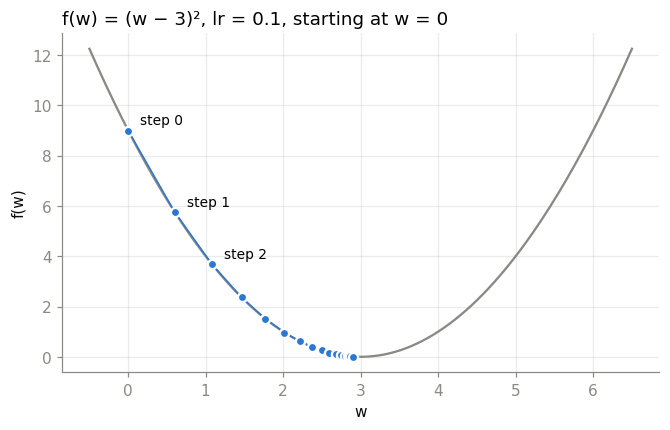

w after each step: [0.    0.6   1.08  1.464 1.771 2.017] ... 2.894


In [24]:
f      = lambda w: (w - 3) ** 2
fprime = lambda w: 2 * (w - 3)

def gd_1d(w0, lr, steps):
    ws = [w0]
    for _ in range(steps):
        ws.append(ws[-1] - lr * fprime(ws[-1]))
    return np.array(ws)

ws = gd_1d(w0=0.0, lr=0.1, steps=15)
grid = np.linspace(-0.5, 6.5, 200)
plt.plot(grid, f(grid), color=MUTED, lw=1.5)
plt.plot(ws, f(ws), "o-", color=BLUE, ms=6, mec="white", mew=1.5, lw=1)
for i in range(3):
    plt.annotate(f"step {i}", (ws[i], f(ws[i])), textcoords="offset points", xytext=(8, 4), fontsize=9)
plt.title("f(w) = (w − 3)², lr = 0.1, starting at w = 0", loc="left")
plt.xlabel("w"); plt.ylabel("f(w)")
plt.show()
print("w after each step:", np.round(ws[:6], 3), "...", round(ws[-1], 3))

---
## Problem 1: The gradient

For $f(w) = (w-3)^2$, what is $f'(0)$?

In [8]:
w = 0 
f_prime_at_0 = 2 * (w-3) 

answer_1 = f_prime_at_0   # f'(0) = ?

check("1", answer_1)
# hint("1")
# solution("1")

✅ Problem 1: correct! (-6)


## Problem 2: One step

Start at $w_0 = 0$ with learning rate $\eta = 0.1$. What is $w_1$?

In [12]:
# w_1 = w_0 - lr * f'(w_0) 

w_1 = 0 - 0.1 * answer_1 

answer_2 = w_1   # w after one step

check("2", answer_2)
hint("2")
# solution("2")

✅ Problem 2: correct! (0.6)
💡 w_new = w - lr · f'(w) = 0 - 0.1 · (your answer to Problem 1).


We move 0.6 to the right here 

## Problem 3: Two steps

Keep going from $w_1$ with the same $\eta = 0.1$. What is $w_2$?

In [14]:
answer_3 = 0.6 - (0.1 * 2 * (0.6 - 3))    # w after two steps

check("3", answer_3)
# hint("3")
# solution("3")

✅ Problem 3: correct! (1.08)


## Problem 4: The learning rate matters

**(a)** Start at $w_0 = 0$ with $\eta = 1.0$. What is $w_1$?
**(b)** What learning rate takes you from $w_0 = 0$ **exactly** to the minimum $w = 3$ in one step?

In [22]:
answer_4a = 0 - (1 * 2*( 0-3))   # w1 with lr = 1.0
answer_4b = 0.5  # the lr that lands on w = 3 in one step

check("4a", answer_4a)
check("4b", answer_4b)
hint("4a"); hint("4b")
# solution("4a"); solution("4b")

✅ Problem 4a: correct! (6)
✅ Problem 4b: correct! (0.5)
💡 f'(0) = -6 again, but now lr = 1.0.
💡 You want 0 - lr·(-6) = 3. Solve for lr.


### Demo: too small, just right, too big

Same function, same start, four learning rates. Each step multiplies the distance to the minimum by $(1 - 2\eta)$:

- $|1 - 2\eta| < 1$ → converges ($0 < \eta < 1$)
- $1 - 2\eta < 0$ → overshoots and zig-zags, but can still converge
- $|1 - 2\eta| > 1$ → **diverges** ($\eta > 1$)

General rule for a quadratic: $\eta < 2 / f''(w)$. Steeper curvature needs a smaller learning rate.

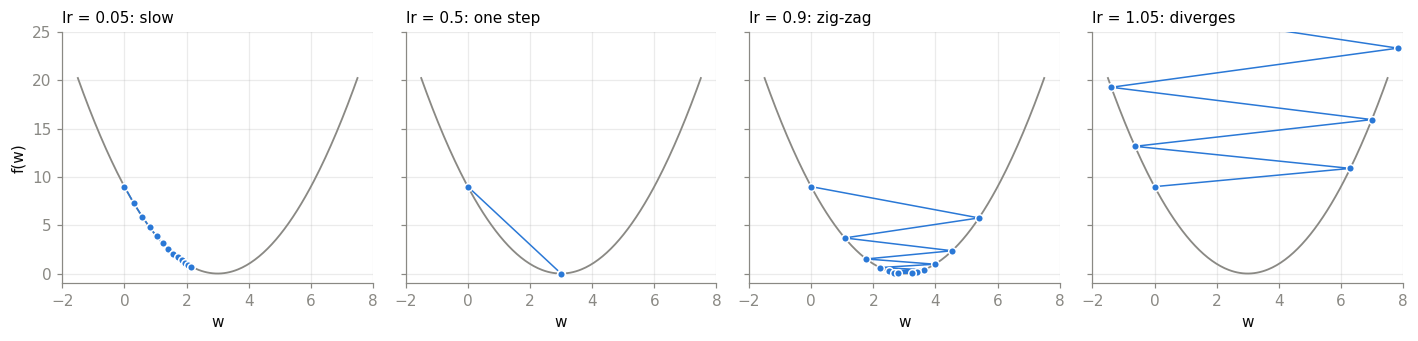

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, lr, verdict in zip(axes, [0.05, 0.5, 0.9, 1.05], ["slow", "one step", "zig-zag", "diverges"]):
    ws = gd_1d(0.0, lr, 12)
    g = np.linspace(-1.5, 7.5, 200)
    ax.plot(g, f(g), color=MUTED, lw=1.2)
    ax.plot(ws, f(ws), "o-", color=BLUE, ms=5, mec="white", mew=1, lw=1)
    ax.set_title(f"lr = {lr}: {verdict}", loc="left", fontsize=10)
    ax.set_ylim(-1, 25); ax.set_xlim(-2, 8); ax.set_xlabel("w")
axes[0].set_ylabel("f(w)")
plt.tight_layout(); plt.show()

---
## Viz V1: Convergence on a log scale

Plot the **distance to the minimum**, $|w_t - 3|$, against step $t$ for learning rates 0.05, 0.2, 0.8 and 1.05, all on one chart.

**Checklist:** 4 lines, log-scale y, axis labels, title, legend.

**Why a log scale?** If every step multiplies the error by the same factor $r$, then $|w_t - 3| = 3r^t$. Take the log and you get $\log 3 + t\log r$: a **straight line** with slope $\log r$. A straight line on a log axis means steady geometric convergence, and a steeper line means faster.

**After you plot:** two of the four lines land exactly on top of each other. Which two, and why? (Compute $|1 - 2\eta|$ for each.)

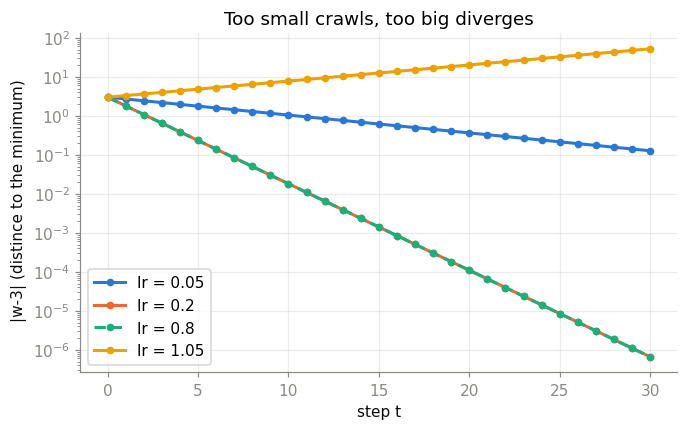

📊 V1 checklist
   ✅ at least 4 lines (found 4)
   ✅ log-scale y axis
   ✅ x and y axis labels
   ✅ a title
   ✅ a legend naming each learning rate (found 4 entries)
All checks pass! Compare with reference('V1') if you like.


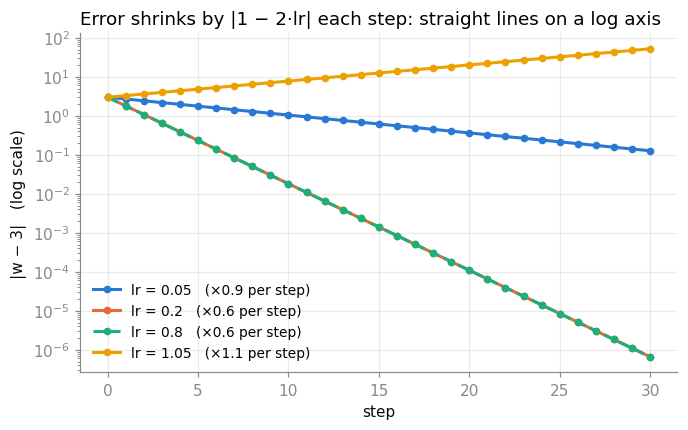

In [44]:
fig, ax = plt.subplots(figsize=(7, 4))
for lr, color, style in zip([0.05, 0.2, 0.8, 1.05], [BLUE, ORANGE, AQUA, YELLOW], ["-", "-", "--", "-"]):
    ws = gd_1d(0.0, lr, 30)          # 31 values of w (gd_1d is from the first demo)
    dist = np.abs(ws - 3)                      # YOUR CODE: distance to the minimum at each step
    steps = range(len(dist))
    ax.plot(steps, dist, style, marker = "o", ms = 4, color = color, label = f"lr = {lr}")
    # YOUR CODE: plot dist against step number, with a label for the legend

ax.set_yscale("log")
ax.set_xlabel("step t")
ax.legend() 
ax.set_title("Too small crawls, too big diverges")
ax.set_ylabel(" |w-3| (distince to the minimum)")
plt.show()


# YOUR CODE: log-scale y, axis labels, title, legend
plt.show()
check_plot("V1", fig)
# hint("V1")
reference("V1")   # draw the reference chart
# solution("V1")    # print its code

Both the leearning rate lr = 0.2, and lr = 0.8 shrinks the distance to the minimum by the same amount each step, x0.6

---
# Part 2: Linear regression as a loss to minimize

Now there are two knobs. We fit a line $\hat y = wx + b$ by minimizing the **mean squared error**:

$$L(w, b) = \frac{1}{n}\sum_{i=1}^{n} (\hat y_i - y_i)^2 = \frac{1}{n}\sum_{i=1}^{n} (w x_i + b - y_i)^2$$

The gradient is the vector of partial derivatives. With the chain rule, letting $e_i = \hat y_i - y_i$ be the error:

$$\frac{\partial L}{\partial w} = \frac{1}{n}\sum_i 2 e_i \cdot \frac{\partial \hat y_i}{\partial w} = \frac{2}{n}\sum_i e_i\, x_i
\qquad
\frac{\partial L}{\partial b} = \frac{2}{n}\sum_i e_i$$

And the update moves both knobs at once:

$$w \leftarrow w - \eta \frac{\partial L}{\partial w}, \qquad b \leftarrow b - \eta \frac{\partial L}{\partial b}$$

> **Convention alert:** some textbooks use $\frac{1}{2n}$ so the 2 cancels. That only rescales the learning rate. This notebook uses $\frac{1}{n}$.

### The data

The setup cell made 200 points from the line $y = 3x + 4$ plus noise. The exact least-squares answer (`w_best`, `b_best`) is our target: a good optimizer should get there.

## Viz V2: Data, fit and residuals

Plot the training data with the best-fit line, and draw each point's **residual**: a vertical segment from the line to the point. MSE is the average of the squared lengths of those segments, so this chart is a picture of the loss.

**Checklist:** scatter of the data, the line, residual segments (`ax.vlines`), axis labels, title, legend.

Tip: draw the residuals first so the dots sit on top of them.

In [49]:
x

array([1.5479121 , 0.87775688, 1.71719584, 1.39473606, 0.1883547 ,
       1.9512447 , 1.5222794 , 1.57212861, 0.25622727, 0.90077188,
       0.74159605, 1.85352998, 1.28773024, 1.64552323, 0.8868284 ,
       0.45447744, 1.10916957, 0.12763451, 1.65526234, 1.2633288 ,
       1.51617548, 0.70905194, 1.94139605, 1.78624224, 1.55676699,
       0.38927742, 0.93344201, 0.08760753, 0.30857898, 1.36609791,
       1.48952431, 1.93501946, 0.65165072, 0.74091941, 0.93911162,
       0.37894272, 0.25984301, 0.95140985, 0.4538187 , 1.33962799,
       0.87430384, 1.66535639, 1.4005302 , 0.62473328, 1.6645196 ,
       1.60952871, 0.77495676, 0.57665621, 1.36499101, 0.27950497,
       0.3998164 , 0.01472454, 1.57384876, 1.32970171, 1.41033076,
       1.56145806, 0.91783155, 1.13748239, 0.279594  , 0.22906015,
       1.33680592, 0.94219241, 1.13047221, 1.52999771, 1.26943664,
       1.1071588 , 1.11841432, 0.6079002 , 0.06163567, 0.87343478,
       0.42916935, 0.81705729, 1.70680615, 0.46787897, 0.11660

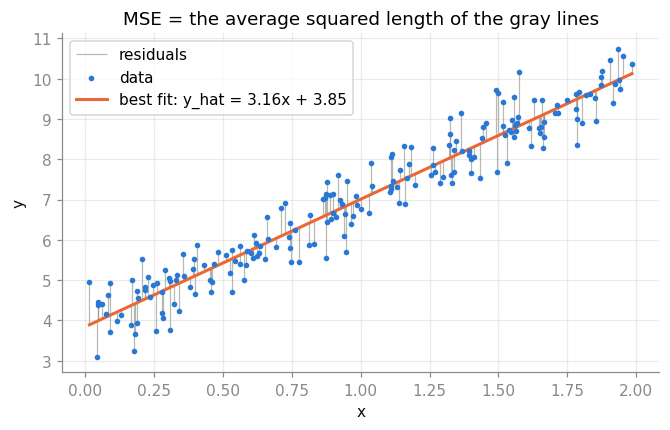

📊 V2 checklist
   ✅ the data as a scatter (ax.scatter)
   ✅ the best-fit line
   ✅ residual segments (ax.vlines)
   ✅ x and y axis labels
   ✅ a title
   ✅ a legend
All checks pass! Compare with reference('V2') if you like.


In [59]:
fig, ax = plt.subplots(figsize=(7, 4))
y_hat = w_best * x + b_best  # YOUR CODE: predictions of the best-fit line at every x

# YOUR CODE:
#   1. residuals: a vertical segment from y_hat to y at each x    ax.vlines(x, ymin, ymax, ...)
ax.vlines(x, y_hat, y, color = MUTED, lw = 0.8, alpha = 0.6, label = 'residuals')
#   2. the data                                                    ax.scatter(...)
ax.scatter(x, y, s=7, color = BLUE, label = 'data', zorder = 3)

#   3. the best-fit line                                           ax.plot(...)
order = np.argsort(x) 
ax.plot(x[order], y_hat[order], color = ORANGE, lw = 2, 
        label = f"best fit: y_hat = {w_best:.2f}x + {b_best:.2f}")
#   4. axis labels, a title, a legend

ax.set_ylabel("y")
ax.set_xlabel("x")
ax.set_title("MSE = the average squared length of the gray lines")
ax.legend(frameon = True)
plt.show()
check_plot("V2", fig)
# hint("V2")
# reference("V2")
# solution("V2")

---
## Problem 5: Loss by hand

Use the tiny dataset: $x = [1, 2, 3]$, $y = [2, 4, 7]$. Starting guess $w = 0,\ b = 0$, so every prediction is $\hat y = 0$.

What is the MSE?

In [ ]:
w, b = 0 , 0 

y_hat = w * x_tiny + b

In [65]:
answer_5 = np.mean((y_hat - y_tiny)**2)   # L(0, 0) on the tiny data. You can use Python as a calculator.

check("5", answer_5)
# hint("5")
# solution("5")

✅ Problem 5: correct! (23)


## Problem 6: Gradient by hand

Same tiny data, same point $w = 0,\ b = 0$.

**(a)** What is $\partial L / \partial w$?
**(b)** What is $\partial L / \partial b$?

In [67]:
e = (0 * x_tiny + 0 - y_tiny)

In [68]:
answer_6a = 2/3 * np.sum(e * x_tiny)   # dL/dw at (0, 0)
answer_6b = 2/3 * np.sum(e)    # dL/db at (0, 0)

check("6a", answer_6a)
check("6b", answer_6b)
hint("6a"); hint("6b")
# solution("6a"); solution("6b")

✅ Problem 6a: correct! (-20.67)
✅ Problem 6b: correct! (-8.667)
💡 ∂L/∂w = (2/n) Σ (ŷᵢ - yᵢ)·xᵢ. With ŷ = 0 the errors are -2, -4, -7; multiply each by its x (1, 2, 3).
💡 ∂L/∂b = (2/n) Σ (ŷᵢ - yᵢ). Same errors as 6a, just no x factor.


## Problem 7: Code the gradient

Write `mse_gradient(w, b, x, y)` that returns `(dL/dw, dL/db)` for any arrays `x`, `y`. Use NumPy, no loops.

Every optimizer below will call this function, so get it right here.

The checker compares your answer to Problem 6, then to a **numerical gradient**:

$$\frac{\partial L}{\partial w} \approx \frac{L(w + h, b) - L(w - h, b)}{2h}$$

This "gradient check" is how people debug hand-derived gradients in practice.

In [74]:
def mse_gradient(w, b, x, y):
    """Return (dL/dw, dL/db) for L = mean((w*x + b - y)**2)."""
    # YOUR CODE HERE
    e = ((w * x) + b - y)
    
    dw = 2/len(x) * np.sum(e * x)
    db = 2/len(x) * np.sum(e) 
    return dw, db

print(mse_gradient(0.0, 0.0, x_tiny, y_tiny))   # should match Problem 6
check_fn("7", mse_gradient)
# hint("7")
# solution("7")

(np.float64(-20.666666666666664), np.float64(-8.666666666666666))
✅ Problem 7: all tests pass!


---
# Part 3: Batch gradient descent

"Batch" means each update uses the **whole dataset** to compute the exact gradient.

```
w, b = 0, 0
repeat for each epoch:
    dw, db = gradient of L using ALL n examples
    w = w - lr * dw
    b = b - lr * db
```

One pass over the data is called an **epoch**. In batch GD, 1 epoch = 1 update.

## Problem 8: Code batch GD

Write `batch_gd(x, y, lr, epochs)`:
- Start at `w = 0.0, b = 0.0`.
- Return the **path**: a NumPy array of `(w, b)` pairs, starting with `(0, 0)` and adding one row after every update. So `epochs` updates → `epochs + 1` rows.
- Use your `mse_gradient`.

In [77]:
def batch_gd(x, y, lr, epochs):
    w, b = 0.0, 0.0
    path = [(w, b)]
    for _ in range(epochs): 
        e = ((w*x)+b-y)
        dw, db = 2/len(x) * np.sum(e * x), 2/len(x) * np.sum(e)
        w = w - lr * dw 
        b = b - lr * db
        path.append((w,b))
        
    return np.array(path)

check_fn("8", batch_gd)
# hint("8")
# solution("8")

✅ Problem 8: all tests pass!


## Viz V3: The loss landscape

Build the chart that explains batch GD: a **contour plot** of $L(w, b)$ with the optimizer's path drawn on top, next to its loss curve. Each contour line is a set of $(w, b)$ pairs with equal loss, like elevation lines on a hiking map.

**Checklist:** two panels. Left: contours, the path, a marker at the minimum. Right: loss per epoch with a log-scale y. Every axis labeled, every panel titled.

**What to look for:** the bowl is a stretched ellipse because $w$ and $b$ are correlated (a steeper slope can be offset by a lower intercept). GD moves perpendicular to the contours, so the path **curves** instead of heading straight for the minimum. On the right, the loss falls fast, then slowly along the flat, stretched direction of the bowl.

**Then try:** change `lr` to `0.4`, then `0.5`, and re-run. For this bowl the stability limit is about 0.46 (it depends on the steepest curvature of $L$, like the 1-D rule $\eta < 2/f''$).

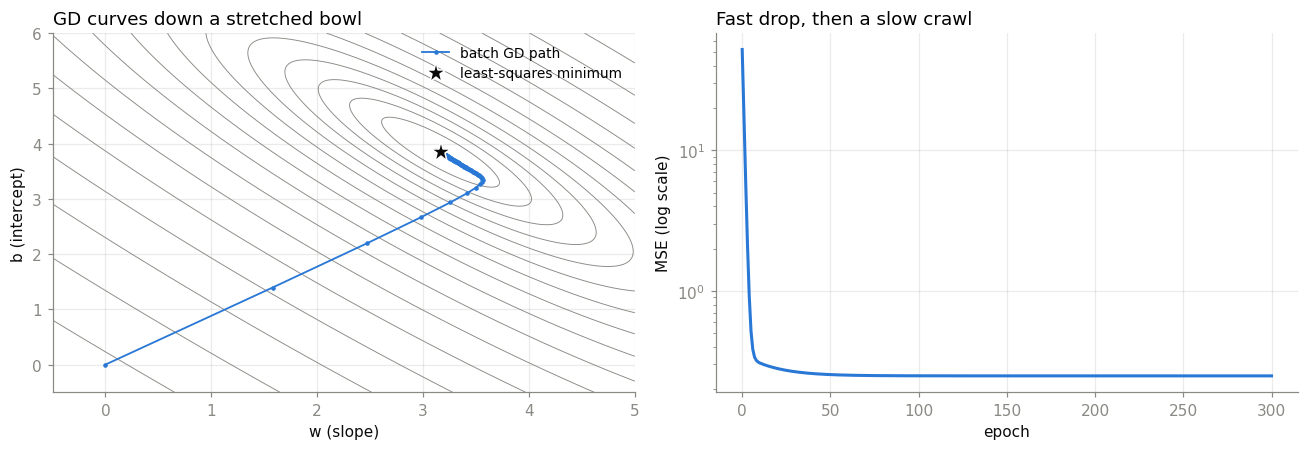

📊 V3 checklist
   ✅ left: contour lines of the loss
   ✅ left: the optimizer path
   ✅ left: a marker at the minimum
   ✅ right: a loss curve
   ✅ right: log-scale y axis
   ✅ axis labels on both panels
   ✅ a title on both panels
All checks pass! Compare with reference('V3') if you like.


In [91]:
path_batch = batch_gd(x, y, lr=0.1, epochs=300)

w_grid = np.linspace(-0.5, 5, 200)
b_grid = np.linspace(-0.5, 6, 200)
W, B = np.meshgrid(w_grid, b_grid)
L = np.mean((W[..., None] * x + B[..., None] - y) ** 2, axis=-1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

# --- Left: the loss landscape ---
levels = np.geomspace(L.min() + 1e-3, L.max(), 18)          # more lines near the bottom
ax1.contour(W, B, L, levels=levels, colors=MUTED, linewidths=0.6)
ax1.plot(path_batch[:, 0], path_batch[:, 1], "o-", color=BLUE, ms=2, lw=1.2, label="batch GD path")
ax1.plot(w_best, b_best, "*", color=INK, ms=14, mec="white", label="least-squares minimum")
ax1.set_xlabel("w (slope)")
ax1.set_ylabel("b (intercept)")
ax1.set_title("GD curves down a stretched bowl", loc="left")
ax1.legend(frameon=False, fontsize=9)

# --- Right: loss per epoch ---
losses = losses_along(path_batch)                            # MSE at every (w, b) in the path
ax2.plot(losses, color=BLUE)
ax2.set_yscale("log")
ax2.set_xlabel("epoch")
ax2.set_ylabel("MSE (log scale)")
ax2.set_title("Fast drop, then a slow crawl", loc="left")

plt.tight_layout()
plt.show()
check_plot("V3", fig)


---
# Part 4: Stochastic gradient descent (SGD)

Batch GD must look at **all n examples before taking a single step**. With millions of examples that is very slow.

SGD's trick: pick **one** example, compute the gradient of *its* loss alone, and step immediately.

$$\nabla L \approx \nabla \ell_i \quad\text{where}\quad \ell_i(w, b) = (w x_i + b - y_i)^2$$

Why it works: if $i$ is chosen at random, $\mathbb{E}[\nabla \ell_i] = \nabla L$. Each step is a **noisy but unbiased** estimate of the true gradient. Lots of cheap noisy steps beat a few expensive exact ones.

```
repeat for each epoch:
    shuffle the examples
    for each example i:
        dw, db = gradient of (w*x_i + b - y_i)^2
        w = w - lr * dw
        b = b - lr * db
```

One epoch is now **n updates**. Shuffling every epoch keeps the order random, so there are no cycles and no bias from how the data was sorted.

## Problem 9: One SGD step by hand

Tiny data again, starting at $w = 0,\ b = 0$, $\eta = 0.01$. The shuffle picks **example 3** first: $x = 3,\ y = 7$.

**(a)** What is $w$ after this one SGD update?
**(b)** What is $b$?

In [92]:
w0, b0, lr9 = 0, 0, 0.01 
x3, y3 = 3, 7

e = w0*x3 + b0 - y3
dw = 2 * e * x3 
db = 2 * e 
answer_9a = w0 - lr9 * dw    # w after one SGD step on (x=3, y=7)
answer_9b = b0 - lr9 * db   # b after one SGD step

check("9a", answer_9a)
check("9b", answer_9b)
# hint("9a"); hint("9b")
# solution("9a"); solution("9b")

✅ Problem 9a: correct! (0.42)
✅ Problem 9b: correct! (0.14)


## Problem 10: Code SGD

Write `sgd(x, y, lr, epochs, seed=0)`:
- Start at `(0.0, 0.0)` and return the path, with one row per **update** (so `epochs * n + 1` rows).
- Make `rng = np.random.default_rng(seed)` once, then use `rng.permutation(n)` at the start of each epoch for the order.
- Reuse `mse_gradient`: pass it a single example as length-1 arrays, `x[i:i+1]` and `y[i:i+1]`.

In [94]:
def sgd(x, y, lr, epochs, seed=0):
    rng = np.random.default_rng(seed)
    n = len(x) 
    w, b = 0.0, 0.0
    path = [(w, b)]
    for _ in range(epochs): 
        for i in rng.permutation(n): 
            dw, db = mse_gradient(w, b, x[i:i+1], y[i:i+1])
            w = w-lr*dw 
            b = b-lr*db
            path.append((w,b))
    # YOUR CODE HERE
    return np.array(path)

check_fn("10", sgd)
# hint("10")
# solution("10")

✅ Problem 10: all tests pass!


### Demo: SGD is fast but jittery

SGD gets close to the minimum within the **first epoch**, while batch GD after 1 epoch has taken exactly one step. But SGD never settles: it keeps bouncing in a small cloud around the star, because each step chases a different example.

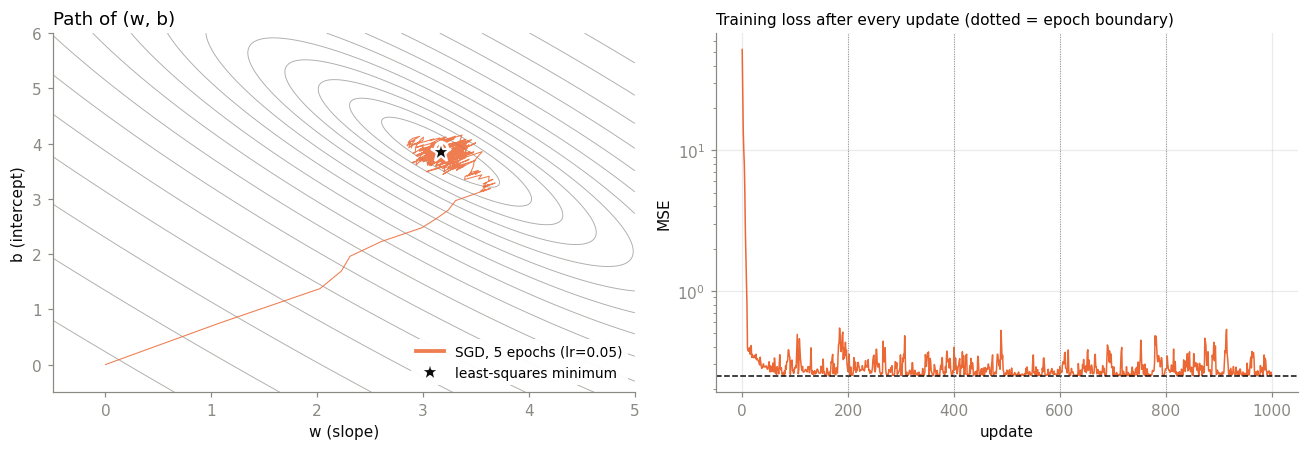

After 1 epoch:  batch GD loss = 17.196   SGD loss = 0.267


In [95]:
if not (solved("8") and solved("10")):
    print("Finish Problems 8 and 10 first, then re-run this cell.")
else:
    path_sgd = sgd(x, y, lr=0.05, epochs=5)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    plot_contour({"SGD, 5 epochs (lr=0.05)": (path_sgd, ORANGE)}, ax=ax1, title="Path of (w, b)")
    ax2.plot(losses_along(path_sgd), color=ORANGE, lw=1)
    ax2.set_yscale("log"); ax2.axhline(mse(w_best, b_best, x, y), color=INK, lw=1, ls="--")
    for e in range(1, 5):
        ax2.axvline(e * n, color=MUTED, lw=0.6, ls=":")
    ax2.set_title("Training loss after every update (dotted = epoch boundary)", loc="left", fontsize=10)
    ax2.set_xlabel("update"); ax2.set_ylabel("MSE")
    plt.tight_layout(); plt.show()

    one_batch, one_sgd = batch_gd(x, y, 0.1, 1)[-1], sgd(x, y, 0.05, 1)[-1]
    print(f"After 1 epoch:  batch GD loss = {mse(*one_batch, x, y):.3f}   SGD loss = {mse(*one_sgd, x, y):.3f}")

---
## Viz V4: How noisy is a mini-batch gradient?

Freeze the parameters at $(w, b) = (1, 1)$ and estimate $\partial L/\partial w$ from 2,000 random mini-batches, for batch sizes 1, 16 and 64. The data prep is done for you. Your job is the chart: **small multiples**, one histogram per batch size, stacked with a shared x-axis so the spreads are directly comparable.

**Checklist:** 3 stacked panels sharing an x-axis, a histogram in each (use the same bin edges in all three so the bars are comparable), a vertical line at the true gradient in each, a title per panel, an x-label on the bottom panel.

**What to look for:** all three histograms are centered on the true gradient (the estimate is *unbiased*), and the spread shrinks as B grows. This chart is the whole case for mini-batches. (Needs Problem 7.)

B =  1:  mean = -11.22   std =  8.24   (true gradient = -11.22)
B = 16:  mean = -11.16   std =  1.98   (true gradient = -11.22)
B = 64:  mean = -11.22   std =  0.87   (true gradient = -11.22)


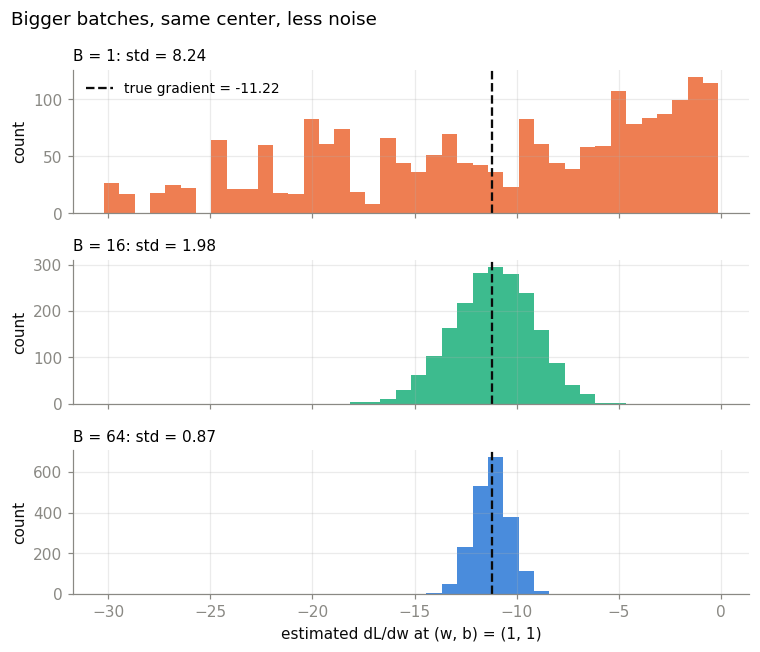

📊 V4 checklist
   ✅ a histogram in every panel
   ✅ a vertical line at the true gradient in every panel (ax.axvline)
   ✅ a shared x-axis
   ✅ a title on every panel
   ✅ an x-label on the bottom panel
All checks pass! Compare with reference('V4') if you like.


In [97]:
assert mse_gradient(0.0, 0.0, x_tiny, y_tiny)[0] is not None, "Finish Problem 7 (mse_gradient) first, then re-run this cell."

w0, b0 = 1.0, 1.0                                   # freeze the parameters here
true_dw = mse_gradient(w0, b0, x, y)[0]             # exact gradient (all 200 examples)
rng_v = np.random.default_rng(1)

def sample_dw(B, draws=2000):
    """dL/dw estimated from `draws` random mini-batches of size B."""
    out = []
    for _ in range(draws):
        idx = rng_v.choice(n, size=B, replace=False)
        out.append(mse_gradient(w0, b0, x[idx], y[idx])[0])
    return np.array(out, dtype=float)

estimates = {B: sample_dw(B) for B in [1, 16, 64]}
for B, est in estimates.items():
    print(f"B = {B:>2}:  mean = {est.mean():6.2f}   std = {est.std():5.2f}   (true gradient = {true_dw:.2f})")

fig, axes = plt.subplots(3, 1, figsize=(7, 6), sharex=True)
# YOUR CODE: for each (ax, B): a histogram of estimates[B], a vertical line at true_dw, a title
#            then an x-label on the bottom panel
bins = np.histogram_bin_edges(np.concatenate(list(estimates.values())), bins=40)

for ax, B, color in zip(axes, [1, 16, 64], [ORANGE, AQUA, BLUE]):
    est = estimates[B]
    ax.hist(est, bins=bins, color=color, alpha=0.85)
    ax.axvline(true_dw, color=INK, lw=1.5, ls="--", label=f"true gradient = {true_dw:.2f}")
    ax.set_title(f"B = {B}: std = {est.std():.2f}", loc="left", fontsize=10)
    ax.set_ylabel("count")

axes[0].legend(frameon=False, fontsize=9)
axes[-1].set_xlabel("estimated dL/dw at (w, b) = (1, 1)")
fig.suptitle("Bigger batches, same center, less noise", x=0.02, ha="left")
plt.tight_layout()
plt.show()

plt.show()
check_plot("V4", fig)
# hint("V4")
# reference("V4")
# solution("V4")

## Problem 10b: Noise vs. batch size

A single-example gradient (B = 1) has standard deviation σ. Averaging B independent examples gives a mini-batch gradient with what standard deviation when **B = 16**? Answer as a multiple of σ (e.g. `0.5` for σ/2).

Then compare with the `std` values printed above your V4 chart.

In [98]:
answer_10b = 1 / np.sqrt(16)    # std for B = 16, as a multiple of σ

check("10b", answer_10b)
# hint("10b")
# solution("10b")

✅ Problem 10b: correct! (0.25)


---
# Part 5: Mini-batch gradient descent

The compromise used almost everywhere in practice (it's what "SGD" means in PyTorch and TensorFlow):

- Shuffle, then cut the data into **batches of size B** (commonly 32 to 512).
- For each batch: gradient = **average** over the B examples in it, then step.

| | Examples per update | Updates per epoch | Gradient noise |
|---|---|---|---|
| Batch GD | n | 1 | none |
| Mini-batch | B | ⌈n / B⌉ | medium |
| SGD | 1 | n | high |

Why mini-batches win:
- **Less noise than SGD.** Averaging B examples shrinks the gradient's variance by a factor of B.
- **Hardware.** GPUs compute 64 examples in about the time it takes to do 1, so you get the averaging nearly for free.
- **Many more updates per epoch than batch GD.**

Vocabulary: an **iteration** (or *step*) is one update. An **epoch** is one full pass over the data.

## Problem 11: Counting updates

You have $n = 200$ examples and batch size $B = 32$. Every example must be used each epoch.

**(a)** How many updates happen in one epoch?
**(b)** How many in 10 epochs?

In [102]:
import math

answer_11a = math.ceil(200/32)   # updates per epoch
answer_11b = 10 * answer_11a   # updates in 10 epochs

check("11a", answer_11a)
check("11b", answer_11b)
# hint("11a"); hint("11b")
# solution("11a"); solution("11b")

✅ Problem 11a: correct! (7)
✅ Problem 11b: correct! (70)


## Problem 12: Code mini-batch GD

Write `minibatch_gd(x, y, lr, epochs, batch_size, seed=0)`:
- Same rules as `sgd` (start at 0, return the path, shuffle with `rng.permutation` each epoch).
- Step through the shuffled order in chunks of `batch_size`. **Keep the last, smaller chunk.**
- Pass the whole chunk to `mse_gradient`, which already averages.

A nice sanity check: `batch_size=n` should behave exactly like batch GD, and `batch_size=1` exactly like SGD.

In [104]:
def minibatch_gd(x, y, lr, epochs, batch_size, seed=0):
    rng = np.random.default_rng(seed)
    n = len(x)
    w, b = 0.0, 0.0
    path = [(w, b)]
    # YOUR CODE HERE
    for _ in range(epochs): 
        order = rng.permutation(n) 
        for start in range(0,n, batch_size): 
            idx = order[start : start + batch_size]
            dw , db = mse_gradient(w, b, x[idx], y[idx])
            w = w - lr * dw
            b = b - lr * db
            path.append((w,b))

    return np.array(path)

check_fn("12", minibatch_gd)
# hint("12")
# solution("12")

✅ Problem 12: all tests pass!


---
# Part 6: Head-to-head

All three run for **10 epochs**, so each one does the same amount of work (2,000 gradient evaluations of single examples). They just spend it differently.

- **Left:** the paths. Batch takes 10 big, smooth steps and stops far from the star. SGD and mini-batch take many small steps and get there.
- **Right:** loss vs. epoch. This is the fair comparison: same compute on the x-axis.

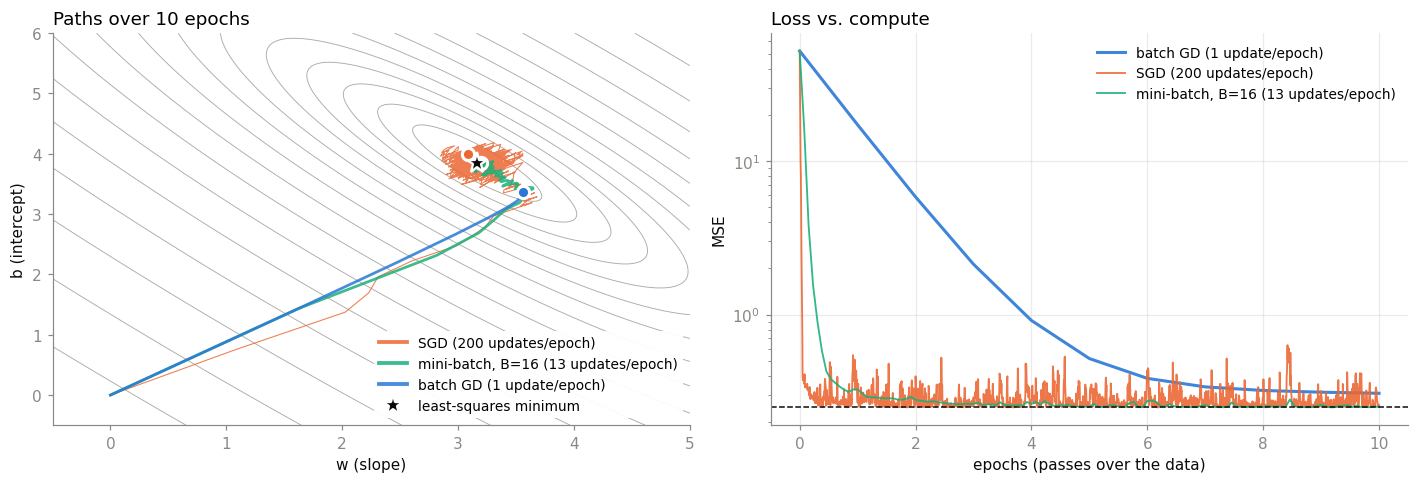

method                                  final w  final b  final loss
batch GD (1 update/epoch)                 3.560    3.360      0.3075
SGD (200 updates/epoch)                   3.087    4.002      0.2572
mini-batch, B=16 (13 updates/epoch)       3.194    3.843      0.2499
target (least squares)                    3.165    3.845      0.2490


In [105]:
if not all(solved(p) for p in ["8", "10", "12"]):
    print("Finish Problems 8, 10 and 12 first, then re-run this cell.")
else:
    E = 10
    runs = {
        "batch GD (1 update/epoch)":       (batch_gd(x, y, lr=0.1, epochs=E), BLUE),
        "SGD (200 updates/epoch)":         (sgd(x, y, lr=0.05, epochs=E), ORANGE),
        "mini-batch, B=16 (13 updates/epoch)": (minibatch_gd(x, y, lr=0.1, epochs=E, batch_size=16), AQUA),
    }
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    plot_contour(runs, ax=ax1, title=f"Paths over {E} epochs")
    for label, (p, color) in runs.items():
        per_update = losses_along(p)
        epoch_axis = np.linspace(0, E, len(p))      # put every run on the same epoch scale
        ax2.plot(epoch_axis, per_update, color=color, lw=1.2 if len(p) > 50 else 2, label=label, alpha=0.9)
    ax2.set_yscale("log"); ax2.axhline(mse(w_best, b_best, x, y), color=INK, lw=1, ls="--")
    ax2.set_xlabel("epochs (passes over the data)"); ax2.set_ylabel("MSE")
    ax2.set_title("Loss vs. compute", loc="left"); ax2.legend(frameon=False, fontsize=9)
    plt.tight_layout(); plt.show()

    print(f"{'method':<38}{'final w':>9}{'final b':>9}{'final loss':>12}")
    for label, (p, _) in runs.items():
        print(f"{label:<38}{p[-1,0]:>9.3f}{p[-1,1]:>9.3f}{mse(*p[-1], x, y):>12.4f}")
    print(f"{'target (least squares)':<38}{w_best:>9.3f}{b_best:>9.3f}{mse(w_best, b_best, x, y):>12.4f}")

### Demo: zoom in on the end

Near the minimum the story flips. Batch GD would eventually land exactly on the star. SGD with a constant learning rate keeps bouncing around it. Mini-batch bounces less, because averaging 16 examples cuts the noise.

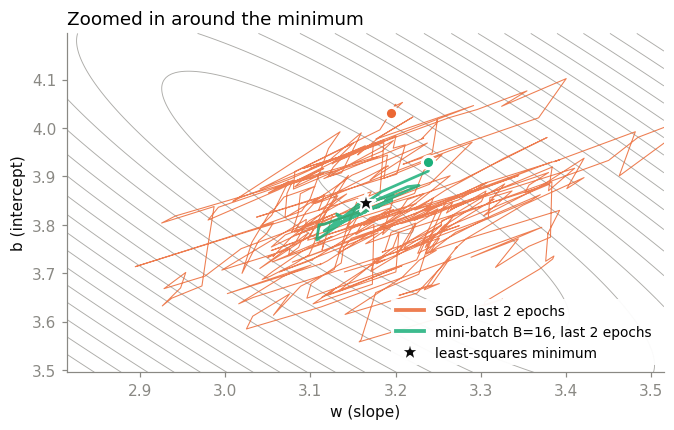

In [106]:
if not all(solved(p) for p in ["8", "10", "12"]):
    print("Finish Problems 8, 10 and 12 first, then re-run this cell.")
else:
    tail = {
        "SGD, last 2 epochs":        (sgd(x, y, lr=0.05, epochs=30)[-2 * n:], ORANGE),
        "mini-batch B=16, last 2 epochs": (minibatch_gd(x, y, lr=0.1, epochs=30, batch_size=16)[-26:], AQUA),
    }
    plot_contour(tail, wlim=(w_best - 0.35, w_best + 0.35), blim=(b_best - 0.35, b_best + 0.35),
                 title="Zoomed in around the minimum")
    plt.show()

---
## Viz V5: The batch-size trade-off

Same budget for every run: 5 epochs at lr = 0.1. How close does each batch size get? We plot the **excess loss** (final loss minus the best possible loss), because every run's raw loss sits near the 0.249 floor, and on a raw scale the differences would be invisible.

**Checklist:** a line with markers, log-scale x and y, annotations naming the two extremes ("SGD" at B = 1, "batch GD" at B = 200), axis labels, title.

Tip: a title that **states the takeaway** is more useful than one that names the chart. Compare "Excess loss vs. batch size" with a sentence that says what the chart shows. (Needs Problem 12.)

{1: 0.0184, 2: 0.0082, 4: 0.0025, 8: 0.0008, 16: 0.0021, 32: 0.0135, 64: 0.033, 200: 0.2685}


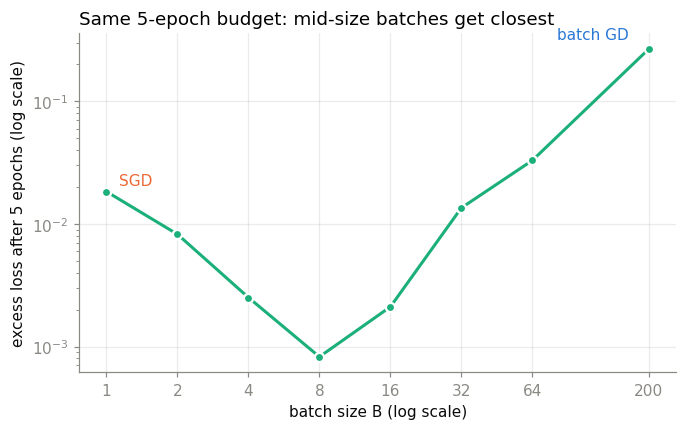

📊 V5 checklist
   ✅ a line through the batch sizes
   ✅ markers on the line
   ✅ log-scale x axis
   ✅ log-scale y axis
   ✅ annotations at both ends (found 2)
   ✅ x and y axis labels
   ✅ a title
All checks pass! Compare with reference('V5') if you like.


In [108]:
batch_sizes = [1, 2, 4, 8, 16, 32, 64, 200]
best = mse(w_best, b_best, x, y)
excess = []
for B in batch_sizes:
    p = minibatch_gd(x, y, lr=0.1, epochs=5, batch_size=B)
    excess.append(mse(*p[-1], x, y) - best)
print({B: round(float(e), 4) for B, e in zip(batch_sizes, excess)})

fig, ax = plt.subplots(figsize=(7, 4))
# YOUR CODE: excess vs batch_sizes as a line with markers
#   - log x (ax.set_xscale("log", base=2) reads nicely) and log y
#   - annotate "SGD" at B = 1 and "batch GD" at B = 200
#   - axis labels and a title that states the takeaway

ax.plot(batch_sizes, excess, "o-", color=AQUA, ms=6, mec="white", mew=1.5)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(batch_sizes, [str(B) for B in batch_sizes])   # show 1, 2, 4, ... 200 instead of 2^k

ax.annotate("SGD", (batch_sizes[0], excess[0]),
            xytext=(8, 4), textcoords="offset points", color=ORANGE)
ax.annotate("batch GD", (batch_sizes[-1], excess[-1]),
            xytext=(-60, 6), textcoords="offset points", color=BLUE)

ax.set_xlabel("batch size B (log scale)")
ax.set_ylabel("excess loss after 5 epochs (log scale)")
ax.set_title("Same 5-epoch budget: mid-size batches get closest", loc="left")
plt.show()


plt.show()
check_plot("V5", fig)
# hint("V5")
# reference("V5")
# solution("V5")

---
# Part 7: Concept check

Answer with a letter, like `choose("13", "a")`.

## Problem 13
Which method's training-loss curve is the **noisiest**?

(a) batch GD  (b) mini-batch GD  (c) SGD

In [111]:
answer_13 = choose("13", "c")   # "a", "b" or "c"
choose("13", answer_13)
# hint("13")

✅ Problem 13: correct!
(c) SGD. Each update uses one example, so its gradient estimate has the most variance.
Problem 13: replace None with a letter, then re-run.


## Problem 14
You double the dataset from 200 to 400 examples. What happens to the cost of **one update**?

(a) both batch GD and SGD updates double in cost
(b) a batch GD update doubles; an SGD update stays the same
(c) neither changes
(d) an SGD update doubles; a batch GD update stays the same

In [112]:
answer_14 = choose("14", "b")
choose("14", answer_14)
# hint("14")

✅ Problem 14: correct!
(b) A batch GD update costs O(n), so it doubles. An SGD update costs O(1) regardless of n.
Problem 14: replace None with a letter, then re-run.


## Problem 15
SGD with a constant learning rate keeps bouncing around the minimum and never settles. What's the standard fix?

(a) increase the learning rate
(b) decay the learning rate over time
(c) train for fewer epochs
(d) stop shuffling the data

In [113]:
answer_15 = choose("15", "b")
choose("15", answer_15)
# hint("15")

✅ Problem 15: correct!
(b) Decay the learning rate. Smaller steps late in training shrink the bouncing around the minimum.
Classic theory needs Σ lr_t = ∞ (can reach anywhere) and Σ lr_t² < ∞ (noise dies out), e.g. lr_t ∝ 1/t.
Problem 15: replace None with a letter, then re-run.


### Bonus demo: learning-rate decay

Same SGD, but the learning rate shrinks each epoch: $\eta_t = \eta_0 / (1 + k\,t)$. Early on it takes big steps to get close fast; later the small steps let it settle.

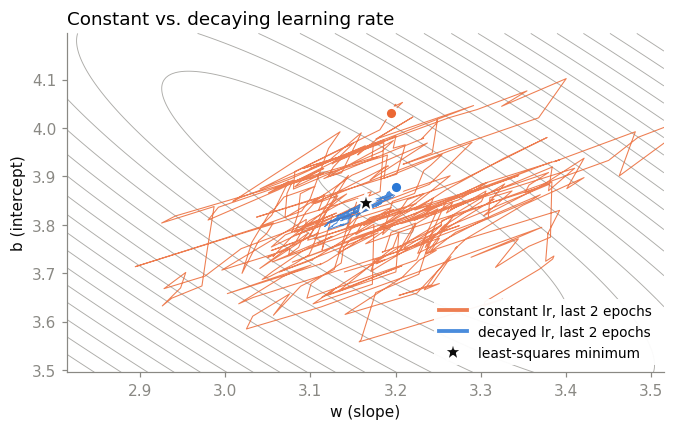

 constant: average distance from the minimum over the last 2 epochs = 0.1345
  decayed: average distance from the minimum over the last 2 epochs = 0.0267


In [114]:
def sgd_decay(x, y, lr0, epochs, k=0.5, seed=0):
    rng = np.random.default_rng(seed)
    w, b = 0.0, 0.0
    path = [(w, b)]
    for epoch in range(epochs):
        lr = lr0 / (1 + k * epoch)                 # the only new line
        for i in rng.permutation(len(x)):
            e = w * x[i] + b - y[i]
            w -= lr * 2 * e * x[i]
            b -= lr * 2 * e
            path.append((w, b))
    return np.array(path)

const = sgd_decay(x, y, lr0=0.05, epochs=30, k=0.0)
decay = sgd_decay(x, y, lr0=0.05, epochs=30, k=0.5)
plot_contour({"constant lr, last 2 epochs": (const[-2 * n:], ORANGE),
              "decayed lr, last 2 epochs": (decay[-2 * n:], BLUE)},
             wlim=(w_best - 0.35, w_best + 0.35), blim=(b_best - 0.35, b_best + 0.35),
             title="Constant vs. decaying learning rate")
plt.show()
for name, p in [("constant", const), ("decayed", decay)]:
    spread = np.linalg.norm(p[-2 * n:] - [w_best, b_best], axis=1).mean()
    print(f"{name:>9}: average distance from the minimum over the last 2 epochs = {spread:.4f}")

---
## Summary

| | Batch GD | Mini-batch GD | SGD |
|---|---|---|---|
| Gradient from | all n examples | B examples | 1 example |
| Updates per epoch | 1 | ⌈n/B⌉ | n |
| Cost per update | O(n) | O(B) | O(1) |
| Path | smooth | slightly noisy | very noisy |
| Near the minimum | settles exactly | small bounce | bigger bounce (decay lr) |
| Typical use | small data, convex problems | **deep learning default** | streaming / online learning |

**Things to remember**
1. The update is always $\theta \leftarrow \theta - \eta \nabla L$. The three methods differ only in **how many examples** estimate $\nabla L$.
2. The learning rate is the most important knob: too small is slow, too big diverges.
3. Noisy gradients are fine (even helpful for escaping bad spots in non-convex problems), but you need to shrink the steps to settle.
4. Always shuffle each epoch for SGD and mini-batch.

## Progress

In [115]:
progress()

✅ 1
✅ 2
✅ 3
✅ 4a
✅ 4b
✅ 5
✅ 6a
✅ 6b
✅ 7
✅ 8
✅ 9a
✅ 9b
✅ 10
✅ 10b
✅ 11a
✅ 11b
✅ 12
✅ 13
✅ 14
✅ 15
✅ V1
✅ V2
✅ V3
✅ V4
✅ V5

25/25 solved
